# Track B+ : radar pulse classification (spectrogram CNN ensemble)

Improved version of `train_b.py`. What changed and why:

| Change | Why |
|---|---|
| Residual CNN, wider, with a **spatial head** (`AdaptiveAvgPool2d((4,4))` + dropout) instead of global average pooling | FM classes differ by the *shape* of the track in time-frequency; global pooling averages that position information away |
| AdamW + **one-cycle LR schedule**, 40 epochs, label smoothing, gradient clipping, **EMA of weights** | the original ran 20 epochs at a constant learning rate; EMA gives a smoother, better final model |
| **Continuous SNR** sampling with a **curriculum** (starts at high SNR, widens to -30 dB) | smoother augmentation, more stable learning of the hard low-SNR cases |
| **Noise-floor whitening** (`WHITEN`): subtract the per-frequency noise level measured in the first 20 us | makes the pulse stand out from the noise floor |
| **Crop to the signal window** (`CROP`): drop the noise-only frames | removes useless input and makes standardization depend only on the pulse |
| All 20 validation pulses per file | less noisy epoch selection |
| **Ensemble** of 3 models with different STFT resolutions (128 / 256 / 512) | different chirp rates are better resolved at different time/frequency tradeoffs; averaging probabilities usually adds the most |

**How to use:** put this notebook anywhere inside (or next to) the `Radar_ML_lite` folder, set `ROOT` in the first cell if needed, then **Run All**. A GPU is strongly recommended. Set `SMOKE = True` first to check that everything runs (about a minute).

**Honest expectations:** the score is the mean over 13 SNRs from +30 to -30 dB. The lowest SNRs are close to impossible for any model, so most of the gain comes from the middle range. The notebook prints and plots the accuracy per SNR so you can see it.

In [1]:
import csv, json, time, copy, math
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ============================== CONFIG (edit here) ==============================
SMOKE = False            # True = quick test: 1 epoch, 2 pulses per file, 1 model

# Folder that contains  dataset/  and  dataset_infos/split_manifest.csv
ROOT = Path.cwd()
# ROOT = Path(r"C:\path\to\Radar_ML_lite")     # <- or set it by hand
for cand in [ROOT, *ROOT.parents]:
    if (cand / "dataset_infos" / "split_manifest.csv").exists():
        ROOT = cand
        break
else:
    raise FileNotFoundError("Cannot find dataset_infos/split_manifest.csv. Set ROOT by hand above.")

DATA_DIR = ROOT / "dataset"
SPLIT_CSV = ROOT / "dataset_infos" / "split_manifest.csv"
OUT = ROOT / "track_b_plus"
OUT.mkdir(exist_ok=True)

N_TRAIN_PER_FILE = 80    # 80 available per file
N_VAL_PER_FILE = 20      # 20 available per file
EPOCHS = 40
BATCH = 64
LR = 2e-3
WD = 1e-2
LABEL_SMOOTH = 0.05
EMA_DECAY = 0.998
EVAL_EVERY = 2           # evaluate every N epochs (and always at the last one)
CROP = True              # keep only the time frames inside the signal window (21-119 us)
WHITEN = True            # subtract the per-frequency noise floor measured in the first 20 us

# (n_fft, hop, seed): one model per entry, then averaged
CONFIGS = [(256, 128, 42), (128, 64, 43), (512, 256, 44)]

if SMOKE:
    N_TRAIN_PER_FILE, N_VAL_PER_FILE, EPOCHS, EVAL_EVERY = 2, 2, 1, 1
    CONFIGS = CONFIGS[:1]

SEED = 42
FS = 120e6
CLASSES = ["barker", "cw", "fmcw", "fsk", "hyp", "nlfm", "quad"]
SNRS = [30, 25, 20, 15, 10, 5, 0, -5, -10, -15, -20, -25, -30]
N0, S0, S1 = int(20e-6 * FS), int(21e-6 * FS), int(119e-6 * FS)   # noise window end / signal window

device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"
print("device:", device, "| mixed precision:", use_amp, "| ROOT:", ROOT)
if device == "cpu":
    print("WARNING: no GPU found, training will be very slow.")
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

device: cuda | mixed precision: True | ROOT: c:\Users\Think pro\Desktop\Radar_ML_Lite_DATATHON\Radar_ML_Lite_supervised_multiclass_classification\Radar_ML_lite


## 1. Load data

In [2]:
def get_label(filename):
    token = filename.split("_")[1].split("#")[0].lower()
    return "barker" if token.startswith("barker") else token


def load_split(rows, per_file):
    """Load a few pulses per file into RAM (int16) + their noise / signal power."""
    by_file = {}
    for r in rows:
        by_file.setdefault(r["file"], []).append(int(r["pulse_index"]))
    X, y, npw, spw = [], [], [], []
    for f, idxs in by_file.items():
        idxs = list(rng.permutation(idxs))[:per_file]
        arr = np.load(DATA_DIR / f, mmap_mode="r")
        label = CLASSES.index(get_label(f))
        for i in idxs:
            raw = np.array(arr[0, int(i)])
            iq = raw[0::2].astype(np.float64) + 1j * raw[1::2].astype(np.float64)
            n = np.mean(np.abs(iq[:N0]) ** 2)
            s = np.mean(np.abs(iq[S0:S1]) ** 2) - n
            if not np.isfinite(s) or s <= 0:
                continue
            X.append(raw); y.append(label); npw.append(n); spw.append(s)
    return (np.stack(X), np.array(y), np.array(npw, np.float32), np.array(spw, np.float32))


with open(SPLIT_CSV, newline="") as f:
    rows = list(csv.DictReader(f))

t0 = time.time()
Xtr, ytr, ntr, str_ = load_split([r for r in rows if r["split"] == "train"], N_TRAIN_PER_FILE)
Xva, yva, nva, sva = load_split([r for r in rows if r["split"] == "validation"], N_VAL_PER_FILE)
print(f"train {len(Xtr)}  val {len(Xva)}  ({time.time() - t0:.0f}s)")
print("train class counts:", dict(zip(CLASSES, np.bincount(ytr, minlength=7).tolist())))
print("val   class counts:", dict(zip(CLASSES, np.bincount(yva, minlength=7).tolist())))

counts = np.bincount(ytr, minlength=7)
class_w = torch.tensor(counts.sum() / (7 * np.maximum(counts, 1)), dtype=torch.float32, device=device)

train 52800  val 13200  (165s)
train class counts: {'barker': 5760, 'cw': 960, 'fmcw': 7680, 'fsk': 15360, 'hyp': 7680, 'nlfm': 7680, 'quad': 7680}
val   class counts: {'barker': 1440, 'cw': 240, 'fmcw': 1920, 'fsk': 3840, 'hyp': 1920, 'nlfm': 1920, 'quad': 1920}


### Sanity check: where is the pulse in time?

`CROP = True` assumes the pulse lives between 21 and 119 us (the two dashed lines). Check on this plot that the power really sits between them. If it does not, set `CROP = False` in the first cell.

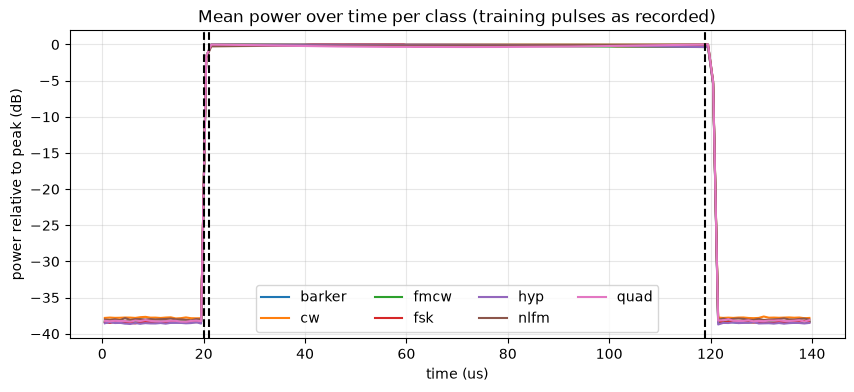

In [3]:
def power_per_us(X):
    p = X[:, 0::2].astype(np.float64) ** 2 + X[:, 1::2].astype(np.float64) ** 2    # (n, 16800)
    return p.reshape(len(X), 140, 120).mean(2)                                      # 120 samples = 1 us

plt.figure(figsize=(10, 4))
for c, name in enumerate(CLASSES):
    sel = np.where(ytr == c)[0][:40]
    if len(sel) == 0:
        continue
    p = power_per_us(Xtr[sel])
    db = 10 * np.log10(p / p.max(1, keepdims=True) + 1e-12).mean(0)
    plt.plot(np.arange(140) + 0.5, db, label=name)
plt.axvline(20, ls="--", c="k"); plt.axvline(21, ls="--", c="k"); plt.axvline(119, ls="--", c="k")
plt.xlabel("time (us)"); plt.ylabel("power relative to peak (dB)"); plt.legend(ncol=4); plt.grid(alpha=.3)
plt.title("Mean power over time per class (training pulses as recorded)")
plt.show()

## 2. Noise and spectrogram

In [4]:
def add_noise(x, npw, spw, snr_db, gen=None):
    """Add Gaussian noise to reach the target SNR (same idea as the organizers' degrade()).
    snr_db can be a float or a tensor of shape (B,)."""
    added = spw / (10.0 ** (snr_db / 10.0)) - npw
    sigma = torch.sqrt(torch.clamp(added, min=0) / 2).unsqueeze(1)
    noise = torch.randn(x.shape, device=x.device, generator=gen) * sigma
    return torch.clamp(x + noise, -32768, 32767)


_WIN = {}
def get_win(n):
    if n not in _WIN:
        _WIN[n] = torch.hann_window(n).to(device)
    return _WIN[n]


def frame_ranges(nfft, hop):
    """Frame indices: how many frames are noise-only, and which frames lie fully inside 21-119 us."""
    n_noise = max(1, (N0 - nfft) // hop + 1)
    k0 = -(-S0 // hop)                       # first frame starting at/after 21 us
    k1 = (S1 - nfft) // hop + 1              # one past the last frame ending before 119 us
    return n_noise, k0, k1


def to_spec(x, nfft, hop):
    """x: (B, 33600) interleaved I/Q -> (B, 1, nfft, frames) normalized log-spectrogram."""
    iq = torch.complex(x[:, 0::2], x[:, 1::2])
    S = torch.stft(iq, n_fft=nfft, hop_length=hop, window=get_win(nfft), center=False,
                   return_complex=True, onesided=False)
    P = torch.fft.fftshift(S.abs() ** 2, dim=1)                       # (B, freq, time)
    n_noise, k0, k1 = frame_ranges(nfft, hop)
    L = 10 * torch.log10(P + 1e-8)
    if WHITEN:
        floor = P[:, :, :n_noise].mean(2, keepdim=True)               # noise power per frequency bin
        L = L - 10 * torch.log10(floor + 1e-8)
    if CROP:
        L = L[:, :, k0:k1]
    L = (L - L.mean((1, 2), keepdim=True)) / (L.std((1, 2), keepdim=True) + 1e-6)
    return L.unsqueeze(1)


# quick shape check
for nfft, hop, _ in CONFIGS:
    with torch.no_grad():
        s = to_spec(torch.from_numpy(Xtr[:2]).to(device).float(), nfft, hop)
    print(f"n_fft={nfft:4d} hop={hop:4d} -> spectrogram {tuple(s.shape[2:])}")

n_fft= 256 hop= 128 -> spectrogram (256, 90)
n_fft= 128 hop=  64 -> spectrogram (128, 182)
n_fft= 512 hop= 256 -> spectrogram (512, 44)


## 3. Model, EMA, evaluation helpers

In [5]:
class ResBlock(nn.Module):
    def __init__(self, i, o, stride):
        super().__init__()
        self.c1 = nn.Conv2d(i, o, 3, stride=stride, padding=1, bias=False)
        self.b1 = nn.BatchNorm2d(o)
        self.c2 = nn.Conv2d(o, o, 3, padding=1, bias=False)
        self.b2 = nn.BatchNorm2d(o)
        if i == o and stride == 1:
            self.short = nn.Identity()
        else:
            self.short = nn.Sequential(nn.Conv2d(i, o, 1, stride=stride, bias=False), nn.BatchNorm2d(o))

    def forward(self, x):
        y = torch.relu(self.b1(self.c1(x)))
        y = self.b2(self.c2(y))
        return torch.relu(y + self.short(x))


class Net(nn.Module):
    def __init__(self, n_classes=7, width=32, drop=0.3):
        super().__init__()
        w = width
        self.stem = nn.Sequential(nn.Conv2d(1, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU())
        self.body = nn.Sequential(ResBlock(w, 2 * w, 2), ResBlock(2 * w, 4 * w, 2),
                                  ResBlock(4 * w, 8 * w, 2), ResBlock(8 * w, 8 * w, 2))
        self.pool = nn.AdaptiveAvgPool2d((4, 4))          # keeps a coarse 4x4 map of WHERE things are
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(drop), nn.Linear(8 * w * 16, n_classes))

    def forward(self, x):
        return self.head(self.pool(self.body(self.stem(x))))


class EMA:
    """Exponential moving average of the weights (and BatchNorm statistics)."""
    def __init__(self, model, decay):
        self.decay = decay
        self.shadow = copy.deepcopy(model).eval()
        for p in self.shadow.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for e, m in zip(self.shadow.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point:
                e.mul_(self.decay).add_(m.detach(), alpha=1 - self.decay)
            else:
                e.copy_(m)


def balanced_acc(probs, y):
    pred = probs.argmax(1)
    recalls = [(pred[y == c] == c).mean() for c in range(len(CLASSES)) if (y == c).any()]
    return float(np.mean(recalls))


@torch.no_grad()
def predict_probs(model, nfft, hop, X, npw, spw):
    """Softmax probabilities for every SNR. Same noise for every model (fixed seeds) so models are comparable."""
    model.eval()
    out = {}
    for snr in SNRS:
        gen = torch.Generator(device=device)
        gen.manual_seed(1100 + snr)                       # 1070..1130, always positive
        ps = []
        for i in range(0, len(X), 256):
            xb = torch.from_numpy(X[i:i + 256]).to(device).float()
            nb = torch.from_numpy(npw[i:i + 256]).to(device)
            sb = torch.from_numpy(spw[i:i + 256]).to(device)
            xb = add_noise(xb, nb, sb, float(snr), gen)
            spec = to_spec(xb, nfft, hop)
            with torch.autocast(device_type="cuda" if use_amp else "cpu", enabled=use_amp):
                logits = model(spec)
            ps.append(torch.softmax(logits.float(), 1).cpu().numpy())
        out[snr] = np.concatenate(ps)
    return out

## 4. Training function

In [6]:
def train_model(nfft, hop, seed, epochs=EPOCHS):
    torch.manual_seed(seed)
    rg = np.random.default_rng(seed)
    model = Net().to(device)
    ema = EMA(model, EMA_DECAY)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    steps_per_epoch = math.ceil(len(Xtr) / BATCH)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=epochs * steps_per_epoch, pct_start=0.15)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    loss_fn = nn.CrossEntropyLoss(weight=class_w, label_smoothing=LABEL_SMOOTH)
    curr_epochs = max(1, epochs // 4)                     # SNR curriculum length
    best = dict(score=-1.0)

    for epoch in range(1, epochs + 1):
        model.train()
        t1, total, seen = time.time(), 0.0, 0
        lo = max(-30.0, 10.0 - 40.0 * min(1.0, epoch / curr_epochs))   # lowest SNR allowed this epoch
        perm = rg.permutation(len(Xtr))
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            if len(idx) < 2:
                continue
            xb = torch.from_numpy(Xtr[idx]).to(device).float()
            nb = torch.from_numpy(ntr[idx]).to(device)
            sb = torch.from_numpy(str_[idx]).to(device)
            yb = torch.from_numpy(ytr[idx]).to(device)
            snr = torch.empty(len(idx), device=device).uniform_(lo, 30.0)   # random SNR per pulse
            xb = add_noise(xb, nb, sb, snr)
            with torch.no_grad():
                spec = to_spec(xb, nfft, hop)
            with torch.autocast(device_type="cuda" if use_amp else "cpu", enabled=use_amp):
                logits = model(spec)
            loss = loss_fn(logits.float(), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            scaler.step(opt); scaler.update(); sched.step()
            ema.update(model)
            total += loss.item() * len(idx); seen += len(idx)

        msg = f"epoch {epoch:2d}/{epochs}  snr_lo {lo:6.1f}  loss {total / max(seen, 1):.3f}"
        if epoch % EVAL_EVERY == 0 or epoch == epochs:
            probs = predict_probs(ema.shadow, nfft, hop, Xva, nva, sva)
            per_snr = {s: balanced_acc(probs[s], yva) for s in SNRS}
            score = float(np.mean(list(per_snr.values())))
            msg += f"  val mean balanced acc {score:.4f}"
            if score > best["score"]:
                best = dict(score=score, per_snr=per_snr, probs=probs, epoch=epoch,
                            state={k: v.detach().cpu().clone() for k, v in ema.shadow.state_dict().items()})
                msg += "  *best*"
        print(msg + f"  ({time.time() - t1:.0f}s)")
    best.update(nfft=nfft, hop=hop, seed=seed)
    return best

## 5. Train every model of the ensemble

This is the long cell. Each model is saved in `track_b_plus/` as soon as it finishes.

In [7]:
results = []
for nfft, hop, seed in CONFIGS:
    print(f"\n===== model  n_fft={nfft}  hop={hop}  seed={seed} =====")
    r = train_model(nfft, hop, seed)
    torch.save(r["state"], OUT / f"best_nfft{nfft}_hop{hop}_seed{seed}.pt")
    results.append(r)
    print(f"-> best val mean balanced accuracy {r['score']:.4f} at epoch {r['epoch']}")
    print("   per SNR:", {k: round(v, 2) for k, v in r["per_snr"].items()})


===== model  n_fft=256  hop=128  seed=42 =====


C:\Users\Think pro\AppData\Local\Temp\ipykernel_42760\3608115309.py:9: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


epoch  1/40  snr_lo    6.0  loss 0.647  (37s)
epoch  2/40  snr_lo    2.0  loss 0.433  val mean balanced acc 0.6663  *best*  (70s)
epoch  3/40  snr_lo   -2.0  loss 0.433  (39s)
epoch  4/40  snr_lo   -6.0  loss 0.439  val mean balanced acc 0.7591  *best*  (68s)
epoch  5/40  snr_lo  -10.0  loss 0.437  (36s)
epoch  6/40  snr_lo  -14.0  loss 0.440  val mean balanced acc 0.8098  *best*  (68s)
epoch  7/40  snr_lo  -18.0  loss 0.453  (38s)
epoch  8/40  snr_lo  -22.0  loss 0.500  val mean balanced acc 0.8571  *best*  (67s)
epoch  9/40  snr_lo  -26.0  loss 0.590  (36s)
epoch 10/40  snr_lo  -30.0  loss 0.671  val mean balanced acc 0.8691  *best*  (64s)
epoch 11/40  snr_lo  -30.0  loss 0.661  (36s)
epoch 12/40  snr_lo  -30.0  loss 0.658  val mean balanced acc 0.8732  *best*  (65s)
epoch 13/40  snr_lo  -30.0  loss 0.654  (38s)
epoch 14/40  snr_lo  -30.0  loss 0.644  val mean balanced acc 0.8765  *best*  (66s)
epoch 15/40  snr_lo  -30.0  loss 0.646  (36s)
epoch 16/40  snr_lo  -30.0  loss 0.642  val 

## 6. Ensemble result

  SNR | n_fft 256 | n_fft 128 | n_fft 512 | ensemble
   30 |     1.000 |     1.000 |     1.000 | 1.000
   25 |     1.000 |     1.000 |     1.000 | 1.000
   20 |     1.000 |     1.000 |     1.000 | 1.000
   15 |     1.000 |     1.000 |     1.000 | 1.000
   10 |     1.000 |     1.000 |     1.000 | 1.000
    5 |     1.000 |     1.000 |     1.000 | 1.000
    0 |     1.000 |     1.000 |     1.000 | 1.000
   -5 |     1.000 |     1.000 |     1.000 | 1.000
  -10 |     1.000 |     0.997 |     1.000 | 1.000
  -15 |     0.990 |     0.967 |     0.998 | 0.998
  -20 |     0.915 |     0.858 |     0.926 | 0.954
  -25 |     0.448 |     0.415 |     0.445 | 0.513
  -30 |     0.190 |     0.183 |     0.185 | 0.205
------------------------------------------------------------
mean  |    0.8879 |    0.8785 |    0.8887 | 0.8977

ENSEMBLE val mean balanced accuracy: 0.8977


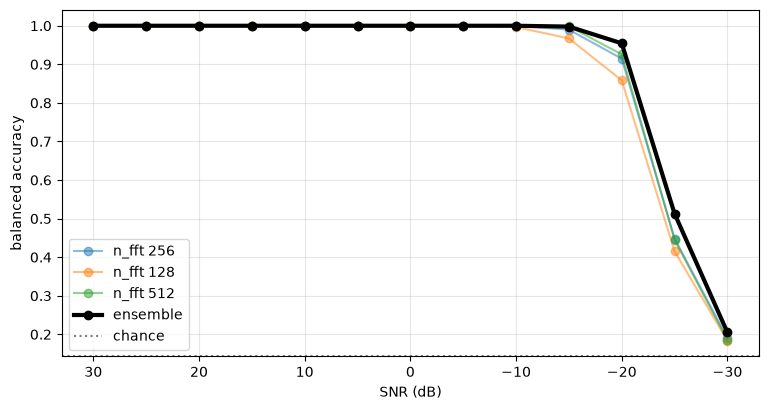

saved: c:\Users\Think pro\Desktop\Radar_ML_Lite_DATATHON\Radar_ML_Lite_supervised_multiclass_classification\Radar_ML_lite\track_b_plus


In [8]:
ens_probs = {s: np.mean([r["probs"][s] for r in results], axis=0) for s in SNRS}
ens_per_snr = {s: balanced_acc(ens_probs[s], yva) for s in SNRS}
ens_score = float(np.mean(list(ens_per_snr.values())))

print(f"{'SNR':>5} | " + " | ".join(f"n_fft {r['nfft']:>3}" for r in results) + " | ensemble")
for s in SNRS:
    print(f"{s:>5} | " + " | ".join(f"{r['per_snr'][s]:>9.3f}" for r in results) + f" | {ens_per_snr[s]:.3f}")
print("-" * 60)
print("mean  | " + " | ".join(f"{r['score']:>9.4f}" for r in results) + f" | {ens_score:.4f}")
print(f"\nENSEMBLE val mean balanced accuracy: {ens_score:.4f}")

plt.figure(figsize=(9, 4.5))
for r in results:
    plt.plot(SNRS, [r["per_snr"][s] for s in SNRS], marker="o", alpha=.5, label=f"n_fft {r['nfft']}")
plt.plot(SNRS, [ens_per_snr[s] for s in SNRS], marker="o", lw=3, c="k", label="ensemble")
plt.axhline(1 / 7, ls=":", c="gray", label="chance")
plt.gca().invert_xaxis(); plt.xlabel("SNR (dB)"); plt.ylabel("balanced accuracy"); plt.grid(alpha=.3); plt.legend()
plt.show()

json.dump(dict(configs=[(r["nfft"], r["hop"], r["seed"]) for r in results], classes=CLASSES, snrs=SNRS,
               crop=CROP, whiten=WHITEN, epochs=EPOCHS, val_mean_balanced_acc=ens_score,
               val_per_snr={str(s): v for s, v in ens_per_snr.items()},
               single_model_scores=[r["score"] for r in results]),
          open(OUT / "ensemble_config.json", "w"), indent=2)
print("saved:", OUT)

## 7. Use the saved ensemble for predictions

`ensemble_predict` takes raw interleaved I/Q pulses `(N, 33600)` (as stored in the `.npy` files) and returns class probabilities. Note that `CROP` and `WHITEN` must be set to the same values as during training (they are saved in `ensemble_config.json`).

In [9]:
def load_ensemble():
    cfg = json.load(open(OUT / "ensemble_config.json"))
    models = []
    for nfft, hop, seed in cfg["configs"]:
        m = Net().to(device)
        m.load_state_dict(torch.load(OUT / f"best_nfft{nfft}_hop{hop}_seed{seed}.pt", map_location=device))
        models.append((m.eval(), nfft, hop))
    return models


@torch.no_grad()
def ensemble_predict(raw, models):
    """raw: (N, 33600) interleaved I/Q (int16 or float). Returns (N, 7) probabilities."""
    total = 0
    for model, nfft, hop in models:
        ps = []
        for i in range(0, len(raw), 256):
            xb = torch.from_numpy(np.asarray(raw[i:i + 256])).to(device).float()
            spec = to_spec(xb, nfft, hop)
            with torch.autocast(device_type="cuda" if use_amp else "cpu", enabled=use_amp):
                logits = model(spec)
            ps.append(torch.softmax(logits.float(), 1).cpu().numpy())
        total = total + np.concatenate(ps)
    return total / len(models)


# example: predictions on the first 5 validation pulses (clean, as recorded)
models = load_ensemble()
p = ensemble_predict(Xva[:5], models)
print([CLASSES[i] for i in p.argmax(1)], "| true:", [CLASSES[i] for i in yva[:5]])

['barker', 'barker', 'barker', 'barker', 'barker'] | true: ['barker', 'barker', 'barker', 'barker', 'barker']


## Ideas to push further

* **A/B test the two risky flags.** Run once with `CROP`/`WHITEN` on and once off (use `SMOKE` or fewer epochs), and keep whichever gives the higher validation score. I could not test on your data, so this is the one thing to verify.
* **More epochs / more models:** `EPOCHS = 60` and more entries in `CONFIGS` (different seeds, or `(1024, 512, ...)`). Ensembles keep improving for a while.
* **Train + validation together** for the final models, using the epoch count that worked best. The validation score is then no longer meaningful, so do this last.
* The validation score of the ensemble is slightly optimistic: the best epoch of each model was chosen on the same validation pulses.